# Creating Figures (Retirement v4)

EV-Taste shock vs Search and Prices. Disregard log-normal taste shock and exogeneous switching probability.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import copy
import time
import datetime

start_time = time.time()

def plot_c_and_mpc(models, colors, linestyles, legend, title, savepath, t=15):
    series = []
    for model, color, ls in zip(models, colors, linestyles):
        m = model.mGrid
        c = model.solution[t].ChoiceSols[1].C
        series.append((m, c, np.gradient(c, m), color, ls))

    plt.figure()
    for m, c, _, color, ls in series:
        plt.plot(m, c, color=color, linestyle=ls)
    plt.xlim([15, 120]); plt.ylim([15, 25])
    plt.xlabel("Resources, $m_t$"); plt.ylabel("Consumption, $C(m_t)$")
    plt.title(title)
    plt.grid(color="k", linestyle=":", linewidth=0.5)
    plt.yticks(np.arange(15, 26, step=1.0))
    plt.legend(legend, loc=4)
    plt.savefig(savepath, dpi=150)
    plt.show()

    plt.figure()
    for m, _, mpc, color, ls in series:
        plt.plot(m, mpc, color=color, linestyle=ls)
    plt.xlim([15, 120]); plt.ylim([-1.5, 1.5])
    plt.xlabel("Resources, $m_t$")
    plt.ylabel(r"Marginal Propensity to Consume, $\partial C / \partial m$")
    plt.title(title)
    plt.grid(color="k", linestyle=":", linewidth=0.5)
    plt.legend(legend, loc=4)
    plt.savefig(savepath.replace(".pdf", "_MPC.pdf"), dpi=150)
    plt.show()


In [2]:
import importlib.util
from pathlib import Path

module_path = Path("Endogenous-Retirement-Search-v4.py")
spec = importlib.util.spec_from_file_location("retirement_search", module_path)
retirement_search = importlib.util.module_from_spec(spec)
spec.loader.exec_module(retirement_search)

RetiringDeaton = retirement_search.RetiringDeaton

fig_dir = Path("../Figures/Figures_v4")
fig_dir.mkdir(parents=True, exist_ok=True)


In [3]:
# +
CRRA = 1.0
DiscFac = 0.98
Rfree = 1.0
DisUtil = 1.0
T = 20
sigma_s = 0.0
sigma_t = 0.0
sigma_xi = 0.0
sigma_phi = 0.0
prob_opt = 1.0
smoothtype = 'type1'

aXtraMin = 1e-6
aXtraMax = 400.0
aXtraCount = 6000
aXtraExtra = () # this is additional points to add (for precision around know problematic areas)
aXtraNestFac = 1 # this is the times to nest

YWork = 20.0
YRet = 0.0 # normalized relative to work
TranShkStd = [0.000]*T
TranShkCount = 1
PermShkStd = [0.0]*T
PermShkCount = 1
TasteShkCount = 1
PhiShkCount = 1
EGMCount = 7000
saveCommon = False #True #False
T_retire = 0 # not applicable, it's endogenous
T_cycle = T
LivPrb = [1.0]*T
PermGroFac = [1.0]*T
UnempPrb = 0.0
UnempPrbRet = 0.0
IncUnemp = 0.0
IncUnempRet = 0.0


retiring_params = {'CRRA' : CRRA,
                   'Rfree' : Rfree,
                   'DiscFac' : DiscFac,
                   'DisUtil' : DisUtil,
                   'T' : T,
                   'sigma_s' : sigma_s,
                   'sigma_t' : sigma_t,
                   'sigma_xi' : sigma_xi,
                   'sigma_phi' : sigma_phi,
                   'prob_opt' : prob_opt,
                   'smoothtype' : smoothtype,
                   'aXtraMin' : aXtraMin,
                   'aXtraMax' : aXtraMax,
                   'aXtraCount' : aXtraCount,
                   'aXtraExtra' : aXtraExtra,
                   'aXtraNestFac' : aXtraNestFac,
                   'UnempPrb' : UnempPrb,
                   'UnempPrbRet' : UnempPrbRet,
                   'IncUnemp' : IncUnemp,
                   'IncUnempRet' : IncUnempRet,
                   'YWork' : YWork,
                   'YRet' : YRet,
                   'TranShkStd' : TranShkStd,
                   'TranShkCount' : TranShkCount,
                   'PermShkStd' : PermShkStd,
                   'PermShkCount' : PermShkCount,
                   'TasteShkCount' : TasteShkCount,
                   'PhiShkCount' : PhiShkCount,
                   'EGMCount' : EGMCount,
                   'T_retire' : T_retire,
                   'T_cycle' : T_cycle,
                   'LivPrb' : LivPrb,
                   'PermGroFac' : PermGroFac,
                   'saveCommon' : saveCommon}
# -

In [4]:
retiring_params

{'CRRA': 1.0,
 'Rfree': 1.0,
 'DiscFac': 0.98,
 'DisUtil': 1.0,
 'T': 20,
 'sigma_s': 0.0,
 'sigma_t': 0.0,
 'sigma_xi': 0.0,
 'sigma_phi': 0.0,
 'prob_opt': 1.0,
 'smoothtype': 'type1',
 'aXtraMin': 1e-06,
 'aXtraMax': 400.0,
 'aXtraCount': 6000,
 'aXtraExtra': (),
 'aXtraNestFac': 1,
 'UnempPrb': 0.0,
 'UnempPrbRet': 0.0,
 'IncUnemp': 0.0,
 'IncUnempRet': 0.0,
 'YWork': 20.0,
 'YRet': 0.0,
 'TranShkStd': [0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0],
 'TranShkCount': 1,
 'PermShkStd': [0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0],
 'PermShkCount': 1,
 'TasteShkCount': 1,
 'PhiShkCount': 1,
 'EGMCount': 7000,
 'T_retire': 0,
 'T_cycle': 20,
 'LivPrb': [1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0],
 'PermGroFac'

In [5]:
#model = dcegm.RetiringDeaton(saveCommon = True)
model = RetiringDeaton(**retiring_params)

In [6]:
model.solve()

## Baseline: EV-Taste shock

Worker consumption $C(m)$ at $t=15$. $\sigma_\zeta$ for taste shock: 0.0, 0.05, 0.1, 0.15

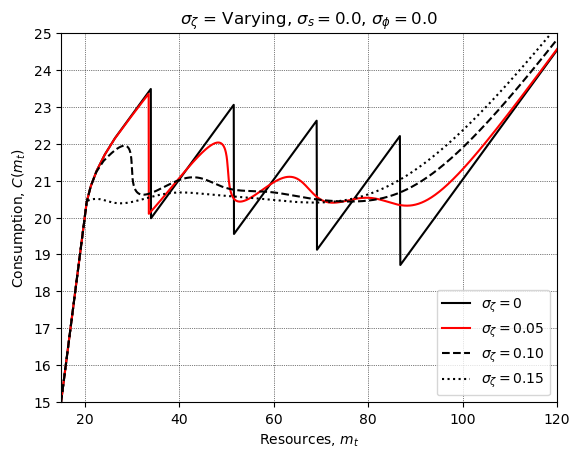

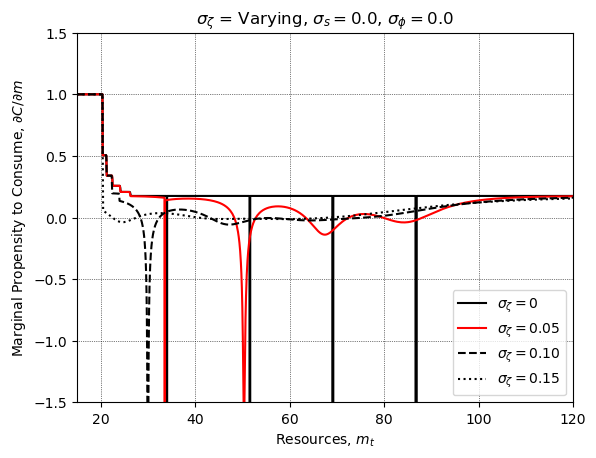

In [7]:
fig_ev_1_params = copy.deepcopy(retiring_params)
fig_ev_1_params['Rfree'] = 1.0
fig_ev_1_params['DiscFac'] = 0.98
fig_ev_1_params['sigma_t'] = 0.0
fig_ev_1_params['sigma_s'] = 0.0
fig_ev_1_params['sigma_phi'] = 0.0
fig_ev_1_params['PhiShkCount'] = 1
fig_ev_1_params['TranShkStd'] = [np.sqrt(0.000)]*fig_ev_1_params['T']
fig_ev_1_params['TranShkCount'] = 1
modelfig_ev_1 = RetiringDeaton(**fig_ev_1_params)
modelfig_ev_1.solve()

fig_ev_2_params = copy.deepcopy(fig_ev_1_params)
fig_ev_2_params['sigma_t'] = 0.05
modelfig_ev_2 = RetiringDeaton(**fig_ev_2_params)
modelfig_ev_2.solve()

fig_ev_3_params = copy.deepcopy(fig_ev_1_params)
fig_ev_3_params['sigma_t'] = 0.1
modelfig_ev_3 = RetiringDeaton(**fig_ev_3_params)
modelfig_ev_3.solve()

fig_ev_4_params = copy.deepcopy(fig_ev_1_params)
fig_ev_4_params['sigma_t'] = 0.15
modelfig_ev_4 = RetiringDeaton(**fig_ev_4_params)
modelfig_ev_4.solve()

t=15

plot_c_and_mpc(
    [modelfig_ev_1, modelfig_ev_2, modelfig_ev_3, modelfig_ev_4],
    ["k", "r", "k", "k"],
    ["-", "-", "--", ":"],
    [r"$\sigma_{\zeta} = 0$", r"$\sigma_{\zeta} = 0.05$", r"$\sigma_{\zeta} = 0.10$", r"$\sigma_{\zeta} = 0.15$"],
    r"$\sigma_{\zeta}$ = Varying, $\sigma_s = 0.0$, $\sigma_{\phi} = 0.0$",
    "../Figures/Figures_v4/EV_VaryT.pdf",
    t=t,
)


## Search alone

Worker consumption $C(m)$ at $t=15$. Sigma for search: 0.0, 0.15, 0.5, 1.0


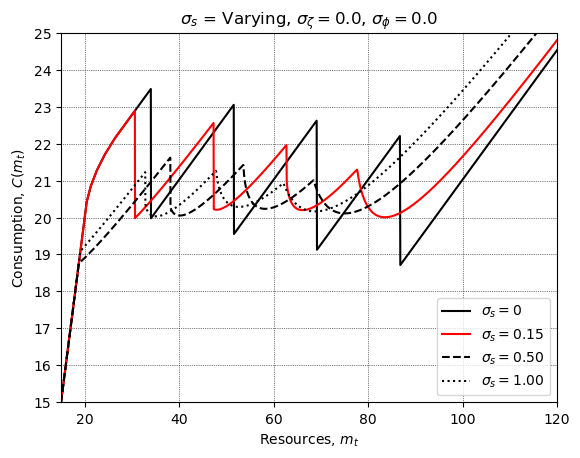

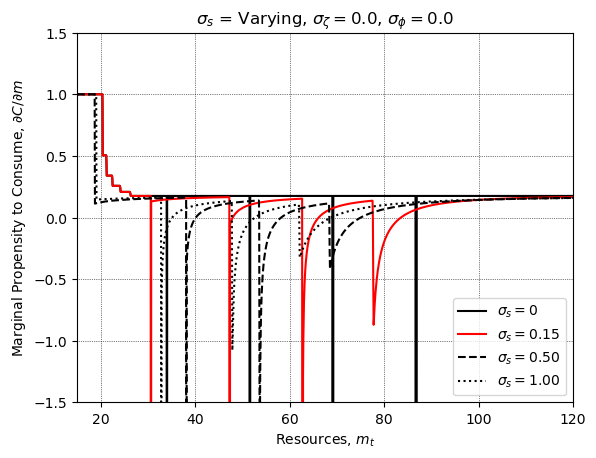

In [8]:
# Search is the only arrival channel (exogenous option probability shut off).
fig_s_1_params = copy.deepcopy(retiring_params)
fig_s_1_params['Rfree'] = 1.0
fig_s_1_params['DiscFac'] = 0.98
fig_s_1_params['prob_opt'] = 0.0
fig_s_1_params['sigma_t'] = 0.0
fig_s_1_params['sigma_s'] = 0.0
fig_s_1_params['sigma_phi'] = 0.0
fig_s_1_params['PhiShkCount'] = 1
fig_s_1_params['TranShkStd'] = [np.sqrt(0.000)]*fig_s_1_params['T']
fig_s_1_params['TranShkCount'] = 1
modelfig_s_1 = RetiringDeaton(**fig_s_1_params)
modelfig_s_1.solve()

fig_s_2_params = copy.deepcopy(fig_s_1_params)
fig_s_2_params['sigma_s'] = 0.15
modelfig_s_2 = RetiringDeaton(**fig_s_2_params)
modelfig_s_2.solve()

fig_s_3_params = copy.deepcopy(fig_s_1_params)
fig_s_3_params['sigma_s'] = 0.5
modelfig_s_3 = RetiringDeaton(**fig_s_3_params)
modelfig_s_3.solve()

fig_s_4_params = copy.deepcopy(fig_s_1_params)
fig_s_4_params['sigma_s'] = 1.0
modelfig_s_4 = RetiringDeaton(**fig_s_4_params)
modelfig_s_4.solve()

t=15

plot_c_and_mpc(
    [modelfig_s_1, modelfig_s_2, modelfig_s_3, modelfig_s_4],
    ["k", "r", "k", "k"],
    ["-", "-", "--", ":"],
    [r"$\sigma_s = 0$", r"$\sigma_s = 0.15$", r"$\sigma_s = 0.50$", r"$\sigma_s = 1.00$"],
    r"$\sigma_s$ = Varying, $\sigma_{\zeta} = 0.0$, $\sigma_{\phi} = 0.0$",
    "../Figures/Figures_v4/Search_VaryS.pdf",
    t=t,
)


## Price alone

a) Varying price dispersion: Worker consumption $C(m)$ at $t=15$. $\sigma_\phi \in \{0, 0.05, 0.1, 0.15\}$ with 151 quadrature nodes

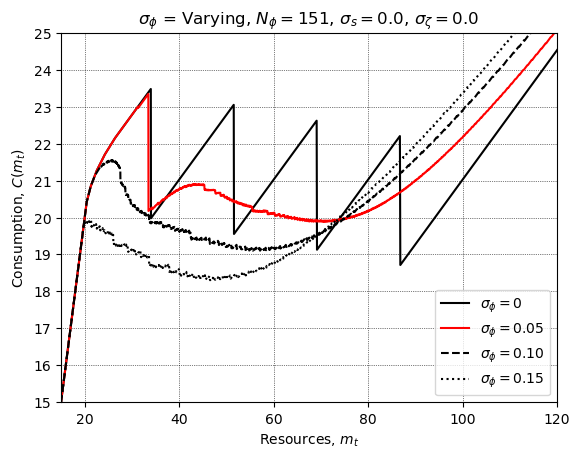

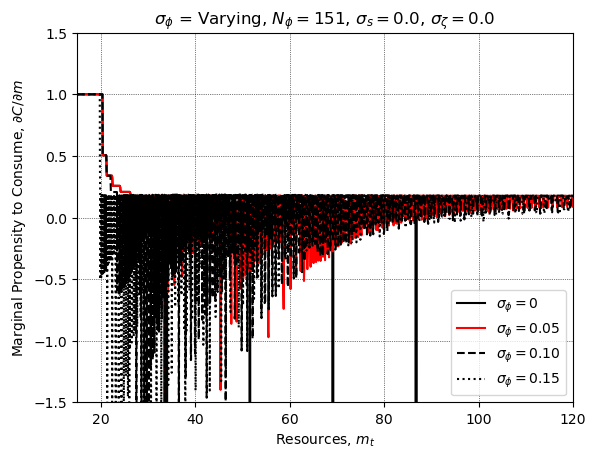

In [9]:
# Price dispersion only: option always available; no search, no EV taste.
fig_phi_1_params = copy.deepcopy(retiring_params)
fig_phi_1_params['Rfree'] = 1.0
fig_phi_1_params['DiscFac'] = 0.98
fig_phi_1_params['sigma_t'] = 0.0
fig_phi_1_params['sigma_s'] = 0.0
fig_phi_1_params['TranShkStd'] = [0.0]*fig_phi_1_params['T']
fig_phi_1_params['TranShkCount'] = 1
fig_phi_1_params['sigma_phi'] = 0.0
fig_phi_1_params['PhiShkCount'] = 1
modelfig_phi_1 = RetiringDeaton(**fig_phi_1_params)
modelfig_phi_1.solve()

fig_phi_2_params = copy.deepcopy(fig_phi_1_params)
fig_phi_2_params['sigma_phi'] = 0.05
fig_phi_2_params['PhiShkCount'] = 151
modelfig_phi_2 = RetiringDeaton(**fig_phi_2_params)
modelfig_phi_2.solve()

fig_phi_3_params = copy.deepcopy(fig_phi_1_params)
fig_phi_3_params['sigma_phi'] = 0.1
fig_phi_3_params['PhiShkCount'] = 151
modelfig_phi_3 = RetiringDeaton(**fig_phi_3_params)
modelfig_phi_3.solve()

fig_phi_4_params = copy.deepcopy(fig_phi_1_params)
fig_phi_4_params['sigma_phi'] = 0.15
fig_phi_4_params['PhiShkCount'] = 151
modelfig_phi_4 = RetiringDeaton(**fig_phi_4_params)
modelfig_phi_4.solve()

t=15

plot_c_and_mpc(
    [modelfig_phi_1, modelfig_phi_2, modelfig_phi_3, modelfig_phi_4],
    ["k", "r", "k", "k"],
    ["-", "-", "--", ":"],
    [r"$\sigma_{\phi} = 0$", r"$\sigma_{\phi} = 0.05$", r"$\sigma_{\phi} = 0.10$", r"$\sigma_{\phi} = 0.15$"],
    r"$\sigma_{\phi}$ = Varying, $N_{\phi} = 151$, $\sigma_s = 0.0$, $\sigma_{\zeta} = 0.0$",
    "../Figures/Figures_v4/Price_VaryPhi.pdf",
    t=t,
)


## Price alone

b) Varying quadrature nodes: Worker consumption $C(m)$ at $t=15$. $\sigma_\phi \in \{0.1\}$ with quadrature nodes $\in \{1, 9, 151, 351\}$

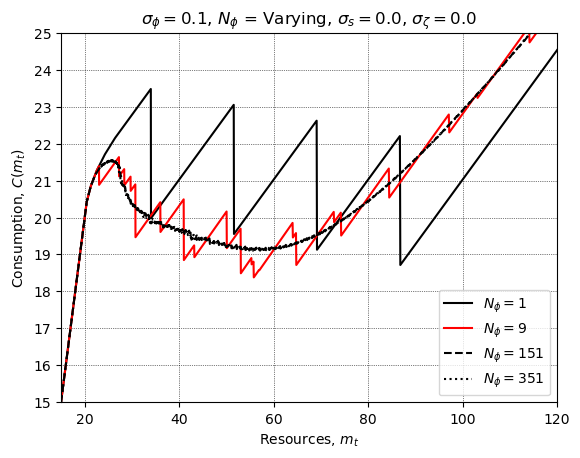

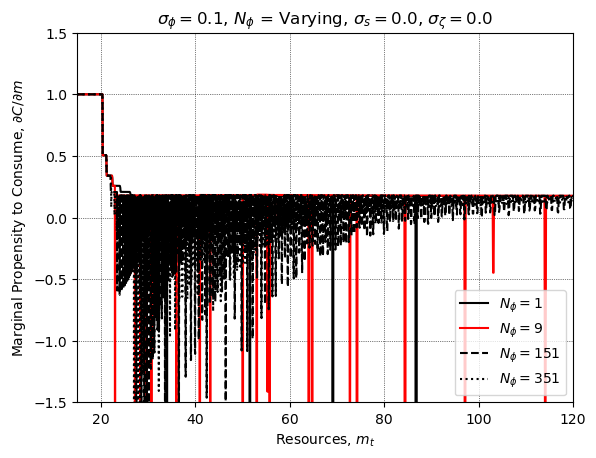

In [10]:
# Price dispersion only: fix sigma_phi = 0.1, vary the number of quadrature nodes.
fig_nphi_1_params = copy.deepcopy(retiring_params)
fig_nphi_1_params['Rfree'] = 1.0
fig_nphi_1_params['DiscFac'] = 0.98
fig_nphi_1_params['sigma_t'] = 0.0
fig_nphi_1_params['sigma_s'] = 0.0
fig_nphi_1_params['TranShkStd'] = [0.0]*fig_nphi_1_params['T']
fig_nphi_1_params['TranShkCount'] = 1
fig_nphi_1_params['sigma_phi'] = 0.1
fig_nphi_1_params['PhiShkCount'] = 1
modelfig_nphi_1 = RetiringDeaton(**fig_nphi_1_params)
modelfig_nphi_1.solve()

fig_nphi_2_params = copy.deepcopy(fig_nphi_1_params)
fig_nphi_2_params['PhiShkCount'] = 9
modelfig_nphi_2 = RetiringDeaton(**fig_nphi_2_params)
modelfig_nphi_2.solve()

fig_nphi_3_params = copy.deepcopy(fig_nphi_1_params)
fig_nphi_3_params['PhiShkCount'] = 151
modelfig_nphi_3 = RetiringDeaton(**fig_nphi_3_params)
modelfig_nphi_3.solve()

fig_nphi_4_params = copy.deepcopy(fig_nphi_1_params)
fig_nphi_4_params['PhiShkCount'] = 351
modelfig_nphi_4 = RetiringDeaton(**fig_nphi_4_params)
modelfig_nphi_4.solve()

t=15

plot_c_and_mpc(
    [modelfig_nphi_1, modelfig_nphi_2, modelfig_nphi_3, modelfig_nphi_4],
    ["k", "r", "k", "k"],
    ["-", "-", "--", ":"],
    [r"$N_{\phi} = 1$", r"$N_{\phi} = 9$", r"$N_{\phi} = 151$", r"$N_{\phi} = 351$"],
    r"$\sigma_{\phi} = 0.1$, $N_{\phi}$ = Varying, $\sigma_s = 0.0$, $\sigma_{\zeta} = 0.0$",
    "../Figures/Figures_v4/Price_VaryPhiCount.pdf",
    t=t,
)


### Search and Price

a) Varying search. Baseline $\sigma_\phi = 0.1$, $N_\phi = 151$. Sigma for search: 0.0, 0.15, 0.5, 1.0


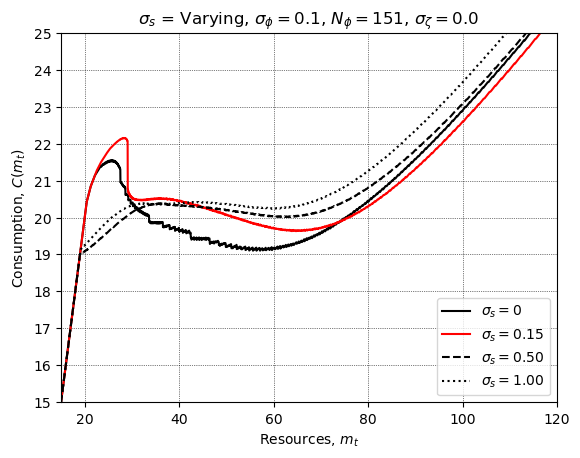

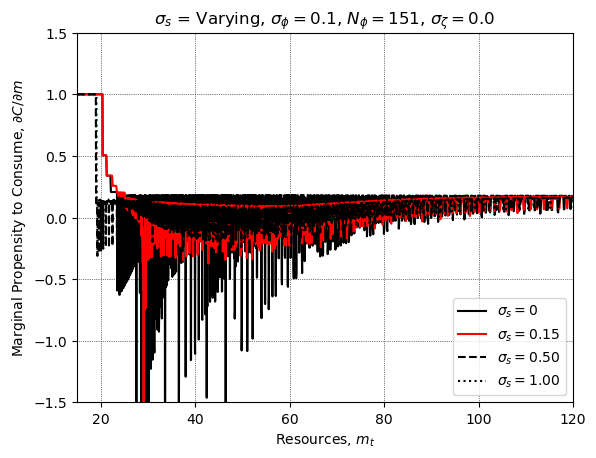

In [11]:
# Search + price. Baseline: sigma_phi = 0.1, N_phi = 151. Search is the arrival channel.
fig_sp_s_1_params = copy.deepcopy(retiring_params)
fig_sp_s_1_params['Rfree'] = 1.0
fig_sp_s_1_params['DiscFac'] = 0.98
fig_sp_s_1_params['prob_opt'] = 0.0
fig_sp_s_1_params['sigma_t'] = 0.0
fig_sp_s_1_params['sigma_s'] = 0.0
fig_sp_s_1_params['TranShkStd'] = [0.0]*fig_sp_s_1_params['T']
fig_sp_s_1_params['TranShkCount'] = 1
fig_sp_s_1_params['sigma_phi'] = 0.1
fig_sp_s_1_params['PhiShkCount'] = 151
modelfig_sp_s_1 = RetiringDeaton(**fig_sp_s_1_params)
modelfig_sp_s_1.solve()

fig_sp_s_2_params = copy.deepcopy(fig_sp_s_1_params)
fig_sp_s_2_params['sigma_s'] = 0.15
modelfig_sp_s_2 = RetiringDeaton(**fig_sp_s_2_params)
modelfig_sp_s_2.solve()

fig_sp_s_3_params = copy.deepcopy(fig_sp_s_1_params)
fig_sp_s_3_params['sigma_s'] = 0.5
modelfig_sp_s_3 = RetiringDeaton(**fig_sp_s_3_params)
modelfig_sp_s_3.solve()

fig_sp_s_4_params = copy.deepcopy(fig_sp_s_1_params)
fig_sp_s_4_params['sigma_s'] = 1.0
modelfig_sp_s_4 = RetiringDeaton(**fig_sp_s_4_params)
modelfig_sp_s_4.solve()

t=15

plot_c_and_mpc(
    [modelfig_sp_s_1, modelfig_sp_s_2, modelfig_sp_s_3, modelfig_sp_s_4],
    ["k", "r", "k", "k"],
    ["-", "-", "--", ":"],
    [r"$\sigma_s = 0$", r"$\sigma_s = 0.15$", r"$\sigma_s = 0.50$", r"$\sigma_s = 1.00$"],
    r"$\sigma_s$ = Varying, $\sigma_{\phi} = 0.1$, $N_{\phi} = 151$, $\sigma_{\zeta} = 0.0$",
    "../Figures/Figures_v4/SearchPhi_VaryS.pdf",
    t=t,
)


b) Varying price. Baseline $\sigma_s = 0.5$. $\sigma_\phi \in \{0, 0.05, 0.1, 0.15\}$ with 151 quadrature nodes


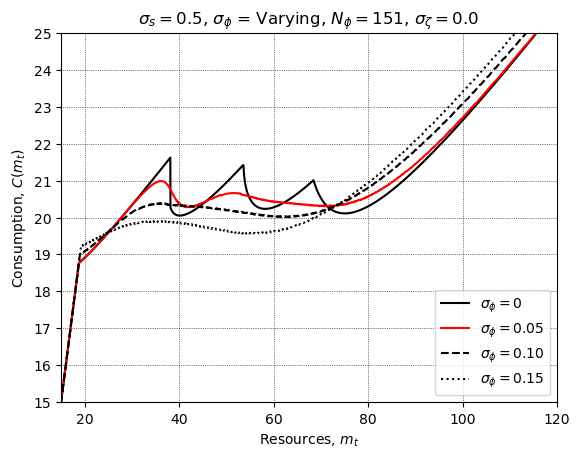

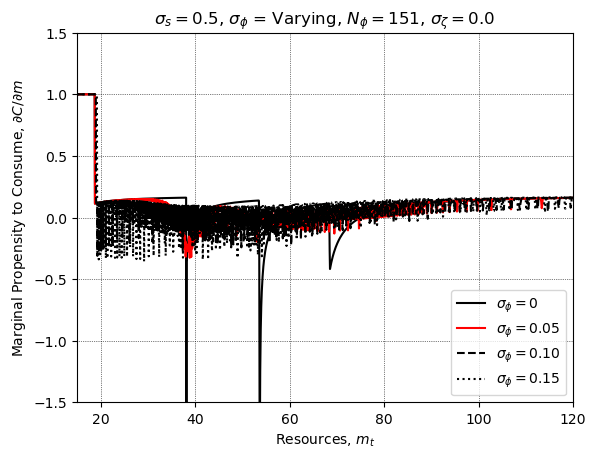

In [12]:
# Search + price. Baseline: sigma_s = 0.5, N_phi = 151. Search is the arrival channel.
fig_sp_phi_1_params = copy.deepcopy(retiring_params)
fig_sp_phi_1_params['Rfree'] = 1.0
fig_sp_phi_1_params['DiscFac'] = 0.98
fig_sp_phi_1_params['prob_opt'] = 0.0
fig_sp_phi_1_params['sigma_t'] = 0.0
fig_sp_phi_1_params['sigma_s'] = 0.5
fig_sp_phi_1_params['TranShkStd'] = [0.0]*fig_sp_phi_1_params['T']
fig_sp_phi_1_params['TranShkCount'] = 1
fig_sp_phi_1_params['sigma_phi'] = 0.0
fig_sp_phi_1_params['PhiShkCount'] = 1
modelfig_sp_phi_1 = RetiringDeaton(**fig_sp_phi_1_params)
modelfig_sp_phi_1.solve()

fig_sp_phi_2_params = copy.deepcopy(fig_sp_phi_1_params)
fig_sp_phi_2_params['sigma_phi'] = 0.05
fig_sp_phi_2_params['PhiShkCount'] = 151
modelfig_sp_phi_2 = RetiringDeaton(**fig_sp_phi_2_params)
modelfig_sp_phi_2.solve()

fig_sp_phi_3_params = copy.deepcopy(fig_sp_phi_1_params)
fig_sp_phi_3_params['sigma_phi'] = 0.1
fig_sp_phi_3_params['PhiShkCount'] = 151
modelfig_sp_phi_3 = RetiringDeaton(**fig_sp_phi_3_params)
modelfig_sp_phi_3.solve()

fig_sp_phi_4_params = copy.deepcopy(fig_sp_phi_1_params)
fig_sp_phi_4_params['sigma_phi'] = 0.15
fig_sp_phi_4_params['PhiShkCount'] = 151
modelfig_sp_phi_4 = RetiringDeaton(**fig_sp_phi_4_params)
modelfig_sp_phi_4.solve()

t=15

plot_c_and_mpc(
    [modelfig_sp_phi_1, modelfig_sp_phi_2, modelfig_sp_phi_3, modelfig_sp_phi_4],
    ["k", "r", "k", "k"],
    ["-", "-", "--", ":"],
    [r"$\sigma_{\phi} = 0$", r"$\sigma_{\phi} = 0.05$", r"$\sigma_{\phi} = 0.10$", r"$\sigma_{\phi} = 0.15$"],
    r"$\sigma_s = 0.5$, $\sigma_{\phi}$ = Varying, $N_{\phi} = 151$, $\sigma_{\zeta} = 0.0$",
    "../Figures/Figures_v4/SearchPhi_VaryPhi.pdf",
    t=t,
)
